# Segmentation crops

Poster panels for one ROI: per method, black outlines of all cells on DAPI (z3), and cells filled by `cell_type_revised`
(grey = removed by QC, i.e. not in `adata_integrated`); plus vascular marker transcripts.
3D methods show the union of all z-planes per cell; larger cells are drawn first so overlaps never hide a cell.

In [1]:
from itertools import product
from pathlib import Path

import anndata as ad
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spatialdata as sd
import spatialdata_plot  # noqa: F401
from matplotlib.colors import LinearSegmentedColormap, to_rgb

from cellseg_benchmark._constants import BASE_PATH, cell_type_colors, methods_3D

/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
sample, roi = "aging_s5_r1", "pial"
cohort = sample.split("_")[0]
xlim, ylim = (645, 790), (3845, 3990)
img, pts = f"{sample}_z3", f"{sample}_transcripts"

markers = {
    "ECs": ["Cldn5", "Cdh5", "Pecam1", "Kdr", "Nos3"],
    "Pericytes": ["Vtn", "Kcnj8", "Rgs5", "Atp13a5", "Anpep"],
    "SMCs": ["Acta2", "Pdlim3", "Tagln", "Myh11", "Adamts1"],
    "VLMCs": ["Dcn", "Col1a1", "Lama1", "Slc7a11", "Slc6a13"],
}
dapi_cmap = LinearSegmentedColormap.from_list("dapi", ["white", "#4747ff"])
grey_cmap = LinearSegmentedColormap.from_list("grey", ["white", "#b0b0b0"])
out = Path(BASE_PATH) / "samples" / sample / "plots" / "segmentation_crops" / roi
out.mkdir(parents=True, exist_ok=True)

In [3]:
sdata = sd.read_zarr(
    Path(BASE_PATH) / "samples" / sample / "sdata_z3.zarr",
    selection=("images", "points", "shapes"),
)
methods = [
    k.removeprefix("boundaries_") for k in sdata.shapes if k.startswith("boundaries_")
]
integrated = {
    m: Path(BASE_PATH) / "analysis" / cohort / m / "adatas" / "adata_integrated.h5ad.gz"
    for m in methods
}
print("no adata_integrated:", [m for m, p in integrated.items() if not p.exists()])
methods = [m for m, p in integrated.items() if p.exists()]
bbox = dict(
    axes=["x", "y"],
    min_coordinate=[xlim[0], ylim[0]],
    max_coordinate=[xlim[1], ylim[1]],
    target_coordinate_system="micron",
)
crop = sd.SpatialData.init_from_elements(
    {
        k: sd.bounding_box_query(sdata[k], **bbox)
        for k in [img, pts, *[f"boundaries_{m}" for m in methods]]
    }
)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/ubuntu/miniforge3/envs/seg_postp

no adata_integrated: []


INFO     Rasterizing image for faster rendering.                                                                   


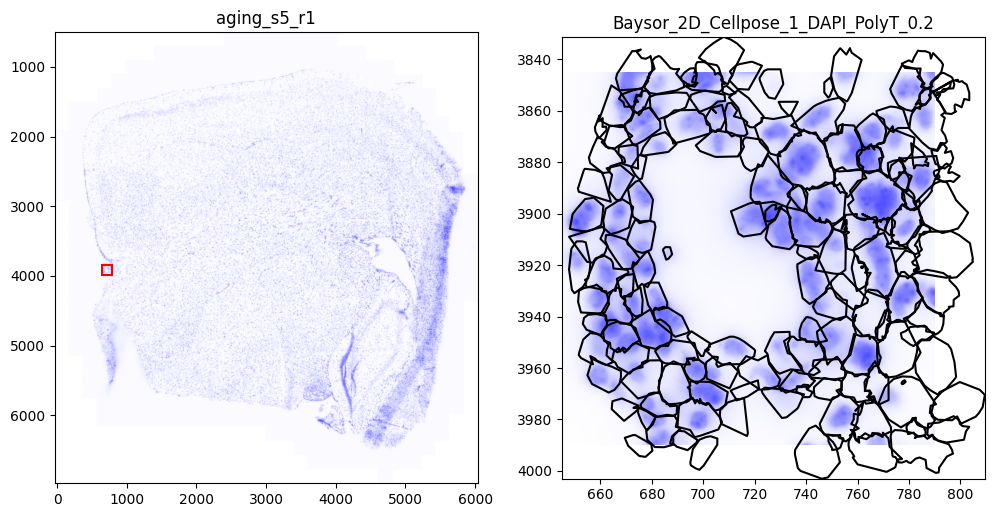

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
sdata.pl.render_images(img, channel="DAPI", cmap=dapi_cmap, colorbar=False).pl.show(
    coordinate_systems="micron", ax=axs[0], title=sample
)
axs[0].add_patch(
    plt.Rectangle(
        (xlim[0], ylim[0]),
        xlim[1] - xlim[0],
        ylim[1] - ylim[0],
        fill=False,
        ec="red",
        lw=1.5,
    )
)
crop.pl.render_images(
    img, channel="DAPI", cmap=dapi_cmap, colorbar=False, scale="full"
).pl.render_shapes(f"boundaries_{methods[0]}", fill_alpha=0, outline_alpha=1).pl.show(
    coordinate_systems="micron", ax=axs[1], title=methods[0]
)

In [5]:
tx = sd.transform(crop[pts], to_coordinate_system="micron").compute()

for name, style in [
    *product(methods, ("outlines", "celltypes")),
    ("vascular", "markers"),
]:
    fig, ax = plt.subplots(figsize=(6, 6))
    if style != "celltypes":
        crop.pl.render_images(
            img,
            channel="DAPI",
            cmap=dapi_cmap if style == "outlines" else grey_cmap,
            colorbar=False,
            scale="full",
        ).pl.show(coordinate_systems="micron", ax=ax, title="")
    if style == "markers":
        for ct, genes in markers.items():
            t = tx[tx["gene"].isin(genes)]
            ax.scatter(
                t.x,
                t.y,
                s=12,
                c=cell_type_colors[ct],
                label=ct,
                edgecolors="#222222",
                linewidths=0.3,
            )
        ax.legend(
            loc="center left", bbox_to_anchor=(1, 0.5), markerscale=2, frameon=False
        )
    else:
        g = sd.transform(crop[f"boundaries_{name}"], to_coordinate_system="micron")
        if name.startswith(tuple(methods_3D)):
            g = g.reset_index(drop=True)[["cell_id", "geometry"]].dissolve("cell_id")
        gi = g.index.astype(str)
        with h5py.File(integrated[name]) as f:
            o = f["obs"]
            mask = ad.io.read_elem(o["sample"]) == sample
            ids = pd.Index(ad.io.read_elem(o[o.attrs["_index"]]))[mask]
            ids = ids.where(ids.isin(gi), ids.str.rsplit("-", n=1).str[0])
            ct = pd.Series(
                ad.io.read_elem(o["cell_type_revised"])[mask].astype(str), index=ids
            )
        ct = ct[ct.index.isin(gi)].reindex(gi)
        print(f"{name} {style}: {ct.notna().sum()}/{len(g)} cells post-QC")
        fill = ct.map(cell_type_colors).fillna("#e0e0e0").to_numpy()
    if style == "outlines":
        g.plot(ax=ax, color="grey", alpha=0.05, lw=0)
        g.boundary.plot(ax=ax, color="black", lw=1)
    if style == "celltypes":
        order = np.argsort(-g.area.to_numpy())
        g.iloc[order].plot(
            ax=ax,
            color=fill[order].tolist(),
            edgecolor=[tuple(0.7 * v for v in to_rgb(c)) for c in fill[order]],
            lw=0.5,
        )
    ax.plot(
        [xlim[1] - 30, xlim[1] - 5],
        [ylim[1] - 5] * 2,
        color="k",
        lw=2,
        solid_capstyle="butt",
    )
    ax.set_aspect("equal")
    ax.set_xlim(*xlim)
    ax.set_ylim(ylim[1], ylim[0])
    ax.axis("off")
    fig.savefig(
        out / f"{sample}_{roi}_{name}_{style}.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.close(fig)

Baysor_2D_Cellpose_1_DAPI_PolyT_0.2 outlines: 145/153 cells post-QC
Baysor_2D_Cellpose_1_DAPI_PolyT_0.2 celltypes: 145/153 cells post-QC
Baysor_2D_Cellpose_1_DAPI_PolyT_0.8 outlines: 132/141 cells post-QC
Baysor_2D_Cellpose_1_DAPI_PolyT_0.8 celltypes: 132/141 cells post-QC
Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2 outlines: 143/151 cells post-QC
Baysor_2D_Cellpose_1_DAPI_Transcripts_0.2 celltypes: 143/151 cells post-QC
Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8 outlines: 126/138 cells post-QC
Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8 celltypes: 126/138 cells post-QC
Baysor_2D_Cellpose_1_nuclei_model_1.0 outlines: 131/140 cells post-QC
Baysor_2D_Cellpose_1_nuclei_model_1.0 celltypes: 131/140 cells post-QC
Baysor_2D_Cellpose_2_DAPI_PolyT_0.2 outlines: 144/150 cells post-QC
Baysor_2D_Cellpose_2_DAPI_PolyT_0.2 celltypes: 144/150 cells post-QC
Baysor_2D_Cellpose_2_DAPI_PolyT_0.8 outlines: 130/139 cells post-QC
Baysor_2D_Cellpose_2_DAPI_PolyT_0.8 celltypes: 130/139 cells post-QC
Baysor_2D_Cel

/tmp/ipykernel_1993437/3779333904.py:51: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  order = np.argsort(-g.area.to_numpy())


Watershed_Merlin outlines: 48/58 cells post-QC
Watershed_Merlin celltypes: 48/58 cells post-QC
vpt_2D_DAPI_PolyT outlines: 109/113 cells post-QC
vpt_2D_DAPI_PolyT celltypes: 109/113 cells post-QC
vpt_2D_DAPI_PolyT_nuclei outlines: 104/108 cells post-QC
vpt_2D_DAPI_PolyT_nuclei celltypes: 104/108 cells post-QC
vpt_2D_DAPI_nuclei outlines: 98/108 cells post-QC
vpt_2D_DAPI_nuclei celltypes: 98/108 cells post-QC
vpt_3D_DAPI_PolyT outlines: 68/107 cells post-QC
vpt_3D_DAPI_PolyT celltypes: 68/107 cells post-QC
vpt_3D_DAPI_PolyT_nuclei outlines: 89/112 cells post-QC
vpt_3D_DAPI_PolyT_nuclei celltypes: 89/112 cells post-QC
vpt_3D_DAPI_nuclei outlines: 87/107 cells post-QC
vpt_3D_DAPI_nuclei celltypes: 87/107 cells post-QC


Plot grid of all methods

In [6]:
import math
import numpy as np
from PIL import Image
from cellseg_benchmark._constants import method_colors, method_names

grid = [m for m in method_colors if m in methods]
ncol, s, ws, hs = 6, 3, 0.02, 0.12
nrow = math.ceil((len(grid) + 1) / ncol)
for style in ("outlines", "celltypes"):
    panels = [("vascular_markers", "Vascular markers")] + [(f"{m}_{style}", method_names[m]) for m in grid]
    fig, axs = plt.subplots(
        nrow,
        ncol,
        figsize=(s * (ncol + ws * (ncol - 1)), s * (nrow + hs * (nrow - 1))),
        gridspec_kw=dict(left=0, right=1, bottom=0, top=1, wspace=ws, hspace=hs),
    )
    for ax in axs.flat:
        ax.axis("off")
    for ax, (f, title) in zip(axs.flat, panels):
        with Image.open(out / f"{sample}_{roi}_{f}.png") as im:
            img = np.asarray(im.convert("RGB").reduce(2))
        ax.imshow(img[:, : img.shape[0]])
        ax.set_title(title, fontsize=17, pad=3)
    fig.savefig(out / f"{sample}_{roi}_grid_{style}.png", dpi=400, bbox_inches="tight")
    plt.close(fig)